01 Exploratory Data Analysis (EDA)¶

In [4]:
# Pandas and numpy for data manipulation
%pip install pandas
%pip install matplotlib seaborn scipy
import pandas as pd
import numpy as np
np.random.seed(123)
# Matplotlib and seaborn for plotting
import matplotlib.pyplot as plt
%matplotlib inline
import matplotlib
matplotlib.rcParams['font.size'] = 8
matplotlib.rcParams['figure.figsize'] = (5, 5)
import seaborn as sns
from IPython.core.pylabtools import figsize
# Scipy helper functions
import scipy
from scipy.stats import percentileofscore
from scipy import stats


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 42.8 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 39.2 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 33.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 41.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 45.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [seaborn]m8/9 [seaborn]ib]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [5]:
import pandas as pd

# Source: Civil Aviation Authority of Singapore, via data.gov.sg
# Each row represents one month at Singapore Changi Airport.
df = pd.read_csv("AirTrafficMovements.csv", thousands=",")

print("Rows and columns:", df.shape)

Rows and columns: (139, 15)


In [6]:
#url = "https://raw.githubusercontent.com/angh0059/KM6312group8/refs/heads/main/AirTrafficMovements.csv?token=GHSAT0AAAAAAELWDTWQBIKGNQMHOGK4JCH42W6AQ4A"
#df = pd.read_csv(url)
df.head()

,Year,Month,Aircraft_Arrival,Aircraft_Departure,Aircraft_Total,Passenger_Arrival,Passenger_Departures,Passenger_Transit,Passenger_Total,AirMail_Incoming,AirMail_Outgoing,AirMail_Total,Cargo_Total_Import,Cargo_Total_Export,Cargo_Total
0,2015,2015-01,14384,14396,28780,2243305,2112813,64004,4420122,1193.6200,1614.88,2808.50,81867.90,69946.38,151814.28
1,2015,2015-02,13249,13242,26491,2018729,2056989,45639,4121357,974.9702,1277.43,2252.40,75576.73,60388.68,135965.42
2,2015,2015-03,14390,14403,28793,2237167,2245963,51989,4535119,1112.6200,1485.10,2597.72,89020.39,73639.48,162659.86
3,2015,2015-04,14126,14130,28256,2181441,2151585,58355,4391381,1095.8200,1391.80,2487.62,83906.47,69541.16,153447.64
4,2015,2015-05,14519,14523,29042,2177764,2250744,51753,4480261,1183.5100,1523.83,2707.34,86950.64,70095.57,157046.21


In [7]:
# check the size of the dataset
print ("Dataset size:", df.shape)

Dataset size: (139, 15)


In [8]:
# Check the data structure (use .info())
print ("Data structure - Airport :")
df.info()

Data structure - Airport :
<class 'pandas.DataFrame'>
RangeIndex: 139 entries, 0 to 138
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Year                  139 non-null    int64  
 1   Month                 139 non-null    str    
 2   Aircraft_Arrival      139 non-null    int64  
 3   Aircraft_Departure    139 non-null    int64  
 4   Aircraft_Total        139 non-null    int64  
 5   Passenger_Arrival     139 non-null    int64  
 6   Passenger_Departures  139 non-null    int64  
 7   Passenger_Transit     139 non-null    int64  
 8   Passenger_Total       139 non-null    int64  
 9   AirMail_Incoming      139 non-null    float64
 10  AirMail_Outgoing      139 non-null    float64
 11  AirMail_Total         139 non-null    float64
 12  Cargo_Total_Import    139 non-null    float64
 13  Cargo_Total_Export    139 non-null    float64
 14  Cargo_Total           139 non-null    float64
dtypes: floa

In [9]:
# Convert the month to a date and sort the rows from oldest to newest.
df["Month"] = pd.to_datetime(df["Month"], format="%Y-%m")
df = df.sort_values("Month").reset_index(drop=True)

# Keep the month number for the team's charts.
df["month_dummy"] = df["Month"].dt.month

# Check the first and last months.
print(df[["Month", "month_dummy"]].iloc[[0, -1]])

         Month  month_dummy
0   2015-01-01            1
138 2026-07-01            7


In [10]:
#convert columns to float
# 1. Count empty values in each column.
print(df.isna().sum())

# 2. Count repeated months.
duplicate_months = df["Month"].duplicated().sum()
print("Duplicate months:", duplicate_months)

# 3. Check whether any month is missing from the study period.
expected_months = pd.date_range("2015-01-01", "2026-07-01", freq="MS")
missing_months = expected_months.difference(df["Month"])
print("Number of missing months:", len(missing_months))

Year                    0
Month                   0
Aircraft_Arrival        0
Aircraft_Departure      0
Aircraft_Total          0
Passenger_Arrival       0
Passenger_Departures    0
Passenger_Transit       0
Passenger_Total         0
AirMail_Incoming        0
AirMail_Outgoing        0
AirMail_Total           0
Cargo_Total_Import      0
Cargo_Total_Export      0
Cargo_Total             0
month_dummy             0
dtype: int64
Duplicate months: 0
Number of missing months: 0


In [12]:
passenger_sum = df["Passenger_Arrival"] + df["Passenger_Departures"] + df["Passenger_Transit"]
passenger_mismatch = df["Passenger_Total"] != passenger_sum
print("Months with a passenger total mismatch:", passenger_mismatch.sum())

Months with a passenger total mismatch: 0


In [13]:
# Aircraft: count the months where arrivals + departures differ from the total.
aircraft_sum = df["Aircraft_Arrival"] + df["Aircraft_Departure"]
aircraft_mismatch = df["Aircraft_Total"] != aircraft_sum
print("Months with an aircraft total mismatch:", aircraft_mismatch.sum())

# Air mail: find the largest difference.
mail_sum = df["AirMail_Incoming"] + df["AirMail_Outgoing"]
mail_difference = df["AirMail_Total"] - mail_sum
print("Largest air mail difference:", round(mail_difference.abs().max(), 4))

# Cargo: find the largest difference.
cargo_sum = df["Cargo_Total_Import"] + df["Cargo_Total_Export"]
cargo_difference = df["Cargo_Total"] - cargo_sum
print("Largest cargo difference:", round(cargo_difference.abs().max(), 4))

Months with an aircraft total mismatch: 0
Largest air mail difference: 0.01
Largest cargo difference: 1.0


In [15]:
#use cosine to show month continuity

# Encode cyclically
df['month_sin'] = np.sin(2 * np.pi * df['month_dummy'] / 12.0)
df['month_cos'] = np.cos(2 * np.pi * df['month_dummy'] / 12.0)

# Track external structural events (COVID timeline indicator)
df['iscovid'] = np.where((df['Year'] >= 2020) & (df['Year'] <= 2022), 1, 0)
df["IsHoliday"] = df["month_dummy"].isin([6, 12]).astype(int)
print("Months marked as school holidays:", df["IsHoliday"].sum())
df.head()

Months marked as school holidays: 23


,Year,Month,Aircraft_Arrival,Aircraft_Departure,Aircraft_Total,Passenger_Arrival,Passenger_Departures,Passenger_Transit,Passenger_Total,AirMail_Incoming,AirMail_Outgoing,AirMail_Total,Cargo_Total_Import,Cargo_Total_Export,Cargo_Total,month_dummy,month_sin,month_cos,iscovid,IsHoliday
0,2015,2015-01-01,14384,14396,28780,2243305,2112813,64004,4420122,1193.6200,1614.88,2808.50,81867.90,69946.38,151814.28,1,0.500000,8.660254e-01,0,0
1,2015,2015-02-01,13249,13242,26491,2018729,2056989,45639,4121357,974.9702,1277.43,2252.40,75576.73,60388.68,135965.42,2,0.866025,5.000000e-01,0,0
2,2015,2015-03-01,14390,14403,28793,2237167,2245963,51989,4535119,1112.6200,1485.10,2597.72,89020.39,73639.48,162659.86,3,1.000000,6.123234e-17,0,0
3,2015,2015-04-01,14126,14130,28256,2181441,2151585,58355,4391381,1095.8200,1391.80,2487.62,83906.47,69541.16,153447.64,4,0.866025,-5.000000e-01,0,0
4,2015,2015-05-01,14519,14523,29042,2177764,2250744,51753,4480261,1183.5100,1523.83,2707.34,86950.64,70095.57,157046.21,5,0.500000,-8.660254e-01,0,0


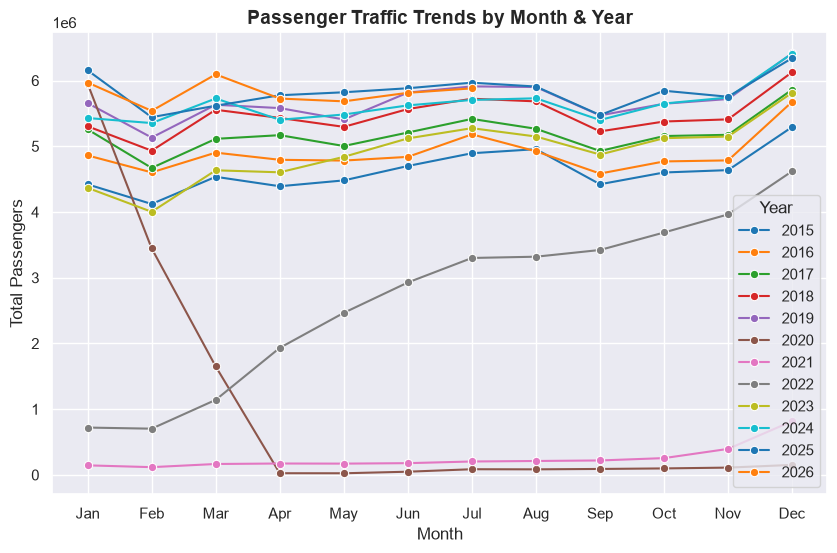

In [12]:
#Visualisation
plt.figure(figsize=(10, 6))
sns.set_theme(style="darkgrid")

# Line plot dividing traffic trends by year
sns.lineplot(
    data=df, 
    x='month_dummy', 
    y='Passenger_Total', 
    hue='Year',        # Separate line for each year
    marker='o',        # Add dots to monthly points
    palette='tab10'
)

plt.title('Passenger Traffic Trends by Month & Year', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Total Passengers')
plt.xticks(ticks=range(1, 13), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.show()

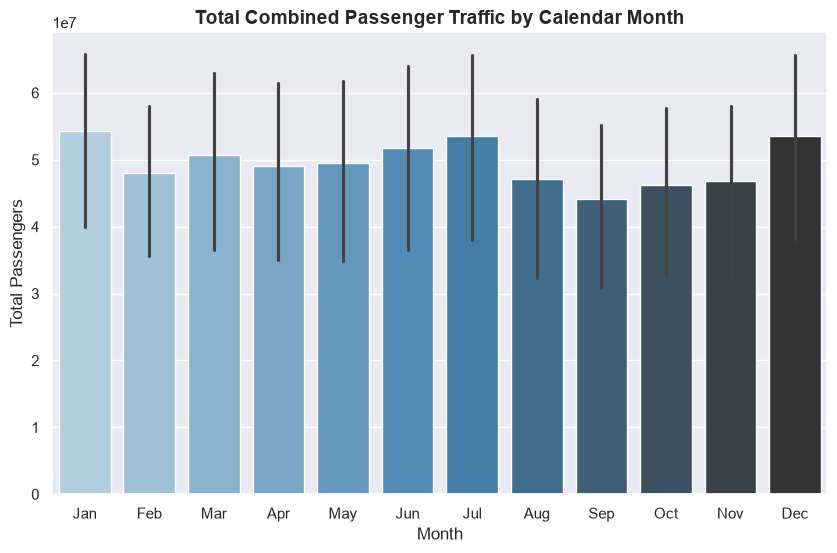

In [14]:
#visualisation 2
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df, 
    x='month_dummy', 
    y='Passenger_Total', 
    estimator=sum,      # Adds up passengers from all years combined
    hue='month_dummy',  # Color individual bars by month name
    legend=False,       # Turn off the redundant side legend
    palette='Blues_d'
)

plt.title('Total Combined Passenger Traffic by Calendar Month', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Total Passengers')
plt.xticks(ticks=range(0, 12), labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.show()